# IMM - Taller No 3 Grupo 02

-----
##Modelo de Michaelis–Menten para la Cinética enzimática (Biología)
-----


En biología, una de las aplicaciones más importantes de las matemáticas está en la enzimología, el estudio de cómo las enzimas catalizan reacciones químicas. La velocidad a la que ocurre una reacción enzimática depende de la concentración de sustrato disponible. El modelo de Michaelis–Menten describe esta relación mediante una fórmula no lineal que involucra dos parámetros fundamentales: $V_{\max}$, la velocidad máxima de la reacción cuando la enzima está saturada de sustrato, y $K_m$, la constante de Michaelis, que indica la concentración de sustrato a la cual la reacción alcanza la mitad de su velocidad máxima. Este modelo es crucial porque permite predecir el comportamiento de reacciones biológicas y comparar la eficiencia de diferentes enzimas.

<br>

El modelo establece que para la velocidad inicial $v$ en función de la concentración de sustrato $S$ es

$$
v = \dfrac{V_{\max}\,S}{K_m + S},
$$

donde $V_{\max}$ y $K_m$ son constantes (velocidad máxima y constante de Michaelis).


Suponga que se realiza un experimento y se obtienen los siguientes datos  (concentración $S$ en $[mM]$ (milimoles), velocidad $v$ en $[\mu \frac{mol}{min}]$):


$$
\begin{array}{|c|c|}
\hline
S\ [mM] & v\ [\mu \frac{mol}{min}]\\
\hline
0.05 & 0.3000\\
0.08 & 0.4286\\
0.10 & 0.5000\\
0.15 & 0.6429\\
0.20 & 0.7500\\
0.30 & 0.9000\\
0.40 & 1.0000\\
0.60 & 1.1250\\
0.80 & 1.2000\\
1.00 & 1.2500\\
1.50 & 1.3235\\
\hline
\end{array}
$$


<br>

### Tareas

1. Proponga un cambio de variable $Y=F(v)$ y $X=G(S)$ que transforme el modelo no lineal a un modelo lineal $Y = mX + b$. Grafique los datos originales $(S,v)$. y los datos transformados $(X,Y)$.

<br>
    **AYUDA:** Manipule la ecuación de tal forma que pueda hacer el cambio de variable: Y=1/v y X=1/s.
<br>


2. Realice una regresión lineal en los datos transformados $(X,Y)$ y estime $V_{\max}$ y $K_m$.


3. Usando el modelo obtenido, estime la velocidad inicial $v$ para $S=2.50\ [\text{mM}]$.

4. Construya el polinomio interpolante de Lagrange que pasa por los primeros cuatro pares de datos $(S,v)$ (para $S=0.05,0.08,0.10,0.15$). Muestre su gráfico.

5. Compare la predicción del polinomio interpolante y la del modelo de regresión lineal para $S=0.12\ [\text{mM}]$. Explique cuál es más confiable.




## Cambio de variables.

$$
v = \dfrac{V_{\max}\,S}{K_m + S},
$$
<br>

$$
\dfrac {1}{v} = \dfrac{K_m + S}{V_{\max\,S}},
$$
<br>

$$
\dfrac {1}{v} = \dfrac{K_m}{V_{\max\, S}} + \dfrac{S}{V_{\max\, S}}
$$
<br>

$$
\dfrac {1}{v} = \dfrac{K_m}{V_{\max\, S}} + \dfrac{1}{V_{\max\,}}
$$
<br>

$$
\dfrac {1}{v} = \dfrac{K_m}{V_{\max}} \dfrac{1}{S} + \dfrac{1}{V_{\max\,}}
$$
<br>

$$ 
y = \dfrac {1}{v}
$$

$$
m = \dfrac{K_m}{V_{\max}}
$$

$$
x = \dfrac {1}{S}
$$

$$
b = \dfrac{1}{V_{\max\,}}
$$

datos de sustrato: 
[0.05 0.08 0.1  0.15 0.2  0.3  0.4  0.6  0.8  1.   1.5 ] miliMoles
datos de velocidad: 
[0.3    0.4286 0.5    0.6429 0.75   0.9    1.     1.125  1.2    1.25
 1.3235] ((uMoles)/min)

Grafica 1. sustrato vs Velocidad


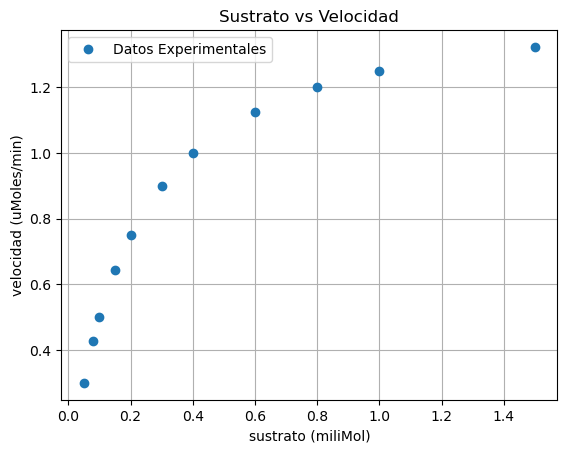

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stat
from scipy.interpolate import lagrange

# Creacion de listas de datos (sustrato en miliMoles) y (velocidad en ((micro-Moles)/min))

sustrato_S = np.array([0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.40, 0.60, 0.80, 1.00, 1.50])
velocidad_V = np.array([0.3000, 0.4286, 0.5000, 0.6429, 0.7500, 0.9000, 1.0000, 1.1250, 1.2000, 1.2500, 1.3235])

print(f'datos de sustrato: \n{sustrato_S} miliMoles')
print(f'datos de velocidad: \n{velocidad_V} ((uMoles)/min)')
print()

# Graficar datos originales 
print('Grafica 1. sustrato vs Velocidad')
plt.plot(sustrato_S, velocidad_V,  marker = 'o', label = 'Datos Experimentales')
plt.title('Sustrato vs Velocidad')
plt.xlabel('sustrato (miliMol)')
plt.ylabel('velocidad (uMoles/min)')
plt.legend()
plt.grid()
plt.show()
print()

cambio de unidades para la velocidad inicial: 
[0.0003    0.0004286 0.0005    0.0006429 0.00075   0.0009    0.001
 0.001125  0.0012    0.00125   0.0013235] mMoles/min

Datos transfomados para Y: 
[3333.33333333 2333.17778815 2000.         1555.45185876 1333.33333333
 1111.11111111 1000.          888.88888889  833.33333333  800.
  755.57234605] min/mMoles
Datos transfrormados para X: 
[20.         12.5        10.          6.66666667  5.          3.33333333
  2.5         1.66666667  1.25        1.          0.66666667] mMoles^-1
Grafica 2. Datos transformados


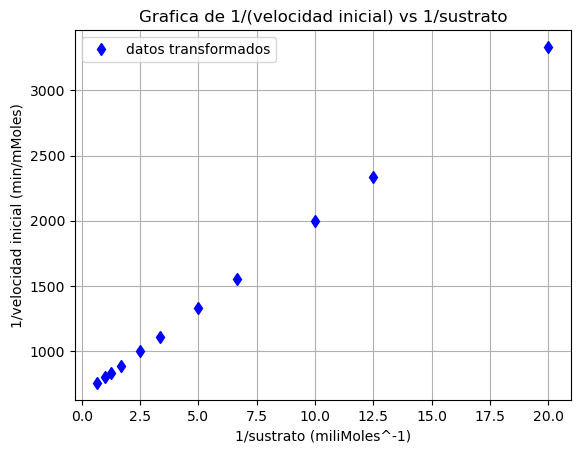

In [4]:
# Cambio de unidades para velocidad uMoles/min
velocidad_V_milimoles = velocidad_V/1000
print(f'cambio de unidades para la velocidad inicial: \n{velocidad_V_milimoles} mMoles/min')
print()

# Datos transformados 
Y = 1/velocidad_V_milimoles
X = 1/sustrato_S
print(f'Datos transfomados para Y: \n{Y} min/mMoles')
print(f'Datos transfrormados para X: \n{X} mMoles^-1')

# Grafica de datos transformados
print('Grafica 2. Datos transformados')
plt.plot(X, Y, 'd', color = 'b', label = 'datos transformados')
plt.title('Grafica de 1/(velocidad inicial) vs 1/sustrato')
plt.xlabel('1/sustrato (miliMoles^-1)')
plt.ylabel('1/velocidad inicial (min/mMoles)')
plt.legend()
plt.grid()
plt.show()

In [49]:
# Regresión lineal

regresion_lineal = stat.linregress(X, Y)
pendiente = regresion_lineal.slope
intercepto = regresion_lineal.intercept

print(f'la pendiente m: {pendiente: .4f}')
print(f'el intercepto b: {intercepto: .4f}')

# Encontramos los valores de 
velocidad_maxima = 1/intercepto
km_constante = pendiente * velocidad_maxima

print(f'el parametro de la velocidad max es igual: {velocidad_maxima: .4f} mMol/min ')
print(f'el parametro de la constante de michaelis Km es igual: {km_constante: .4f} mMoles')


la pendiente m:  133.3301
el intercepto b:  666.6637
el parametro de la velocidad max es igual:  0.0015 mMol/min 
el parametro de la constante de michaelis Km es igual:  0.2000 mMoles


In [50]:
# Estimacion con el modelo encontrado
sustrato = 2.50
velocidad_inicial = (velocidad_maxima * sustrato )/(km_constante + sustrato)
print(f'velocidad inicial para la concentracion de sutrato [2.50 mMoles] es de: {velocidad_inicial: .4f} mMoles/min')

velocidad inicial para la concentracion de sutrato [2.50 mMoles] es de:  0.0014 mMoles/min


los primeros cuatro conjuntos de pares de [0.05 0.08 0.1  0.15] y [0.0003    0.0004286 0.0005    0.0006429]
polinomio de lagrange: 
         3           2
0.04162 x - 0.02391 x + 0.006858 x + 1.169e-05


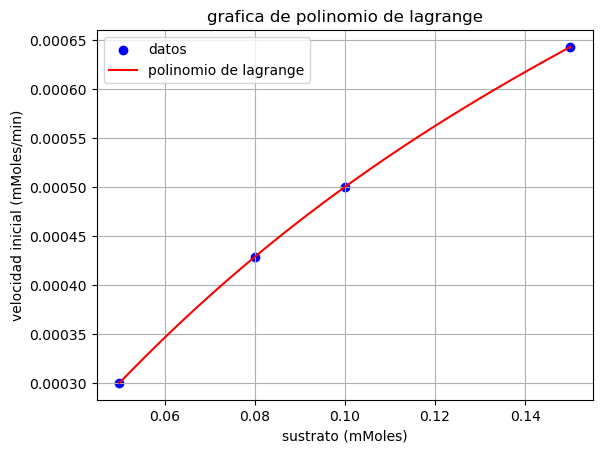

In [85]:
# Interpolacion de lagrange
polinomio_lagrange = lagrange((sustrato_S[:4]), (velocidad_V_milimoles[:4]))
print(f'los primeros cuatro conjuntos de pares de {sustrato_S[:4]} y {velocidad_V_milimoles[:4]}')
print(f'polinomio de lagrange: \n{polinomio_lagrange}')

# Grafica de polinomio de lagrange que pasa por los 4 primeros puntos
sustrato_plot = np.linspace(0.05, 0.15,  100)
velocidad_inicial_plot = polinomio_lagrange(sustrato_plot)

plt.scatter((sustrato_S[:4]), (velocidad_V_milimoles[:4]), marker = 'o', color = 'blue', label = 'datos')
plt.plot(sustrato_plot, velocidad_inicial_plot, linestyle = 'solid',color = 'red', label = 'polinomio de lagrange')
plt.title('grafica de polinomio de lagrange')
plt.legend()
plt.xlabel('sustrato (mMoles)')
plt.ylabel('velocidad inicial (mMoles/min)')
plt.grid()
plt.show()

In [83]:
# comparacion de prediccion con la interpolacion de lagrange y la del modelo de regresión lineal 
sustrato_prediccion = 0.12
prediccion_interpolacion = polinomio_lagrange(sustrato_prediccion)
prediccion_modelo = (velocidad_maxima * sustrato_prediccion) / (km_constante + sustrato_prediccion)
print(f'prediccion interpolacion para la concetracion de sustrato 0.12 [mMoles] es: {prediccion_interpolacion: .4f} mMoles/min')
print(f'prediccion modelos de regresion lineal para la concentración de sustrato 0.12 [mMoles] es: {prediccion_modelo: .4f} mMoles/min')

prediccion interpolacion para la concetracion de sustrato 0.12 [mMoles] es:  0.0006 mMoles/min
prediccion modelos de regresion lineal para la concentración de sustrato 0.12 [mMoles] es:  0.0006 mMoles/min
